# 38. Low Rank, Sparsity and Compressed Sensing
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Why $\ell^1$ finds sparse solutions. In $\mathbb{R}^2$ with one measurement, the solutions of $a^{\mathsf T}x=b$ form a line. Growing the $\ell^2$ ball until it touches the line gives the minimum-norm solution, generically with both coordinates nonzero (left). Growing the $\ell^1$ ball, a diamond with corners on the axes, the first contact is generically at a corner (right): a $1$-sparse solution. In high dimensions the $\ell^1$ ball is "all corners and edges", and contact at low-dimensional faces, i.e. sparse points, is overwhelmingly likely.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


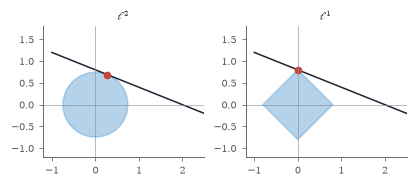

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(W * 0.8, 2.0)); a_ = np.array([1.0, 2.5]); b_ = 2.0; t = np.linspace(-1, 3, 10)
for ax, kind in zip(axs, ["l2", "l1"]):
    ax.plot(t, (b_ - a_[0] * t) / a_[1], color=INK, lw=1)
    if kind == "l2":
        x2 = a_ * b_ / (a_ @ a_); r = np.linalg.norm(x2); th = np.linspace(0, 2 * np.pi, 200); ax.fill(r * np.cos(th), r * np.sin(th), color=SKY, alpha=0.5); ax.plot(*x2, "o", color=RED, ms=4)
    else:
        r = b_ / np.abs(a_).max(); ax.fill([r, 0, -r, 0], [0, r, 0, -r], color=SKY, alpha=0.5); ax.plot(0, r, "o", color=RED, ms=4)
    ax.set_aspect("equal"); ax.set_xlim(-1.2, 2.5); ax.set_ylim(-1.2, 1.8); ax.axhline(0, color=GRAY, lw=0.4); ax.axvline(0, color=GRAY, lw=0.4); ax.set_title(r"$\ell^2$" if kind == "l2" else r"$\ell^1$", fontsize=7)

The Donoho–Tanner phase transition for basis pursuit with $n=60$. For each undersampling ratio $\delta=m/n$ and sparsity ratio $\rho=s/m$, the fraction of $8$ random trials in which $\ell^1$ minimization recovers the sparse vector exactly (solved as a linear program). Recovery succeeds in the dark region and fails in the light one, with a boundary that sharpens as $n$ grows into the theoretical Donoho–Tanner curve.

Text(0, 0.5, '$\\rho=s/m$')

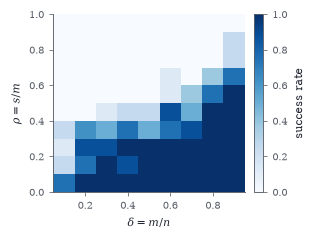

In [3]:
from scipy.optimize import linprog
rng = np.random.default_rng(0); n = 60; deltas = np.linspace(0.1, 0.9, 9); rhos = np.linspace(0.05, 0.95, 10); succ = np.zeros((len(rhos), len(deltas)))
def basis_pursuit(A, b):
    m, n = A.shape; res = linprog(np.ones(2 * n), A_eq=np.hstack([A, -A]), b_eq=b, bounds=(0, None), method="highs"); return res.x[:n] - res.x[n:]
for j, d in enumerate(deltas):
    m = max(2, int(round(d * n)))
    for i, r in enumerate(rhos):
        s = max(1, int(round(r * m))); ok = 0
        for _ in range(8):
            A = rng.normal(size=(m, n)) / np.sqrt(m); x = np.zeros(n); x[rng.choice(n, s, replace=False)] = rng.normal(size=s)
            ok += np.linalg.norm(basis_pursuit(A, A @ x) - x) < 1e-4 * np.linalg.norm(x)
        succ[i, j] = ok / 8
fig, ax = plt.subplots(figsize=(W * 0.6, W * 0.45))
im = ax.imshow(succ, origin="lower", extent=[0.05, 0.95, 0.0, 1.0], aspect="auto", cmap="Blues", vmin=0, vmax=1); fig.colorbar(im, ax=ax, label="success rate")
ax.set_xlabel(r"$\delta=m/n$"); ax.set_ylabel(r"$\rho=s/m$")

Sparse recovery with the LASSO. Left: a $25$-sparse signal of length $500$ (black stems) and its recovery from $m=150$ noisy Gaussian measurements by FISTA (red dots); the least squares minimum-norm solution (grey) is not sparse and bears little resemblance to the signal. Right: objective gap against iteration for ISTA (blue) and FISTA (red). FISTA is much faster; both eventually converge linearly, once the correct support has been identified and the problem becomes strongly convex on it, which is better than their worst-case rates $1/k$ and $1/k^2$.

(1e-12, 10)

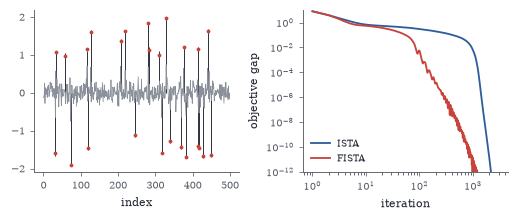

In [4]:
rng = np.random.default_rng(1); n, m, s = 500, 150, 25; A = rng.normal(size=(m, n)) / np.sqrt(m); x0 = np.zeros(n); supp = rng.choice(n, s, replace=False); x0[supp] = rng.choice([-1, 1], s) * rng.uniform(1, 2, s)
b = A @ x0 + 0.02 * rng.normal(size=m); lam = 0.02; L = np.linalg.norm(A, 2) ** 2
soft = lambda v, t: np.sign(v) * np.maximum(np.abs(v) - t, 0); F = lambda x: 0.5 * np.sum((A @ x - b) ** 2) + lam * np.abs(x).sum()
def ista(iters, fast):
    x = np.zeros(n); y = x.copy(); t = 1.0; vals = []
    for _ in range(iters):
        xn = soft(y - A.T @ (A @ y - b) / L, lam / L)
        if fast: tn = (1 + np.sqrt(1 + 4 * t * t)) / 2; y = xn + (t - 1) / tn * (xn - x); t = tn
        else: y = xn
        x = xn; vals.append(F(x))
    return x, np.array(vals)
xf, vf = ista(3000, True); _, vi = ista(3000, False); Fstar = min(vf.min(), vi.min())
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
axs[0].vlines(np.arange(n), 0, x0, color=INK, lw=0.6); axs[0].plot(np.arange(n), np.linalg.pinv(A) @ b, color=GRAY, lw=0.5); axs[0].plot(supp, xf[supp], ".", color=RED, ms=3); axs[0].set_xlabel("index")
axs[1].loglog(np.arange(1, 3001), vi - Fstar + 1e-16, color=BLUE, label="ISTA"); axs[1].loglog(np.arange(1, 3001), vf - Fstar + 1e-16, color=RED, label="FISTA"); axs[1].set_xlabel("iteration"); axs[1].set_ylabel("objective gap"); axs[1].legend(fontsize=6); axs[1].set_ylim(1e-12, 10)

Robust PCA by principal component pursuit on a synthetic "video": $60$ frames of a $30\times30$ scene with a smoothly varying rank-$2$ background and a small bright square moving across it (the sparse foreground). Columns of $M$ are frames. Top: three frames of $M$. Middle: the recovered low-rank background $L$. Bottom: the recovered sparse part $S$, which isolates the moving object. Computed with $150$ ADMM iterations alternating singular value and soft thresholding.

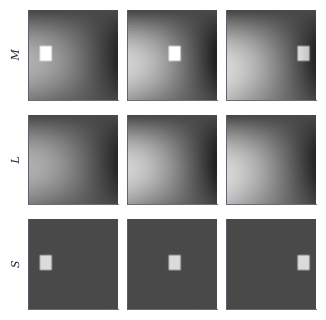

In [5]:
rng = np.random.default_rng(2); h = 30; T = 60; gx = np.linspace(0, 1, h); base1 = np.outer(np.sin(3 * gx), np.cos(2 * gx)).ravel(); base2 = np.outer(gx, 1 - gx).ravel()
L0 = np.outer(base1, 1 + 0.3 * np.sin(np.linspace(0, 3, T))) + np.outer(base2, np.linspace(0.5, 1.5, T)); S0 = np.zeros_like(L0)
for t in range(T):
    fr = np.zeros((h, h)); c = int(2 + 24 * t / T); fr[12:17, c:c + 4] = 2.0; S0[:, t] = fr.ravel()
M = L0 + S0; mm, nn = M.shape; lam_r = 1 / np.sqrt(max(mm, nn)); mu = mm * nn / (4 * np.abs(M).sum())
Lr = np.zeros_like(M); Sr = np.zeros_like(M); Yr = np.zeros_like(M)
for _ in range(150):
    Ub, sb, Vb = np.linalg.svd(M - Sr + Yr / mu, full_matrices=False); Lr = (Ub * np.maximum(sb - 1 / mu, 0)) @ Vb
    Rr = M - Lr + Yr / mu; Sr = np.sign(Rr) * np.maximum(np.abs(Rr) - lam_r / mu, 0); Yr += mu * (M - Lr - Sr)
fig, axs = plt.subplots(3, 3, figsize=(W * 0.62, W * 0.62))
for j, t in enumerate([5, 30, 55]):
    for i, Z in enumerate([M, Lr, Sr]): axs[i, j].imshow(Z[:, t].reshape(h, h), cmap="gray", vmin=-1, vmax=2.5); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
for i, lab in enumerate(["$M$", "$L$", "$S$"]): axs[i, 0].set_ylabel(lab, fontsize=7)

In [6]:
import time
rng = np.random.default_rng(0); n, k = 2000, 10; d = rng.uniform(0.5, 2, n); F = rng.normal(size=(n, k)); v = rng.normal(size=n)
t0 = time.perf_counter(); Dinv_v = v / d; Cap = np.eye(k) + F.T @ (F / d[:, None]); x_w = Dinv_v - (F / d[:, None]) @ np.linalg.solve(Cap, F.T @ Dinv_v)
logdet_w = np.log(d).sum() + np.linalg.slogdet(Cap)[1]; t1 = time.perf_counter()
Sig = np.diag(d) + F @ F.T; x_d = np.linalg.solve(Sig, v); logdet_d = np.linalg.slogdet(Sig)[1]; t2 = time.perf_counter()
print(f"solutions agree: {np.allclose(x_w, x_d)}   logdets: {logdet_w:.6f} vs {logdet_d:.6f}   time {1e3*(t1-t0):.1f} ms vs {1e3*(t2-t1):.1f} ms")

solutions agree: True   logdets: 380.346387 vs 380.346387   time 0.6 ms vs 1058.2 ms


In [7]:
def omp(A, b, s):
    r = b.copy(); S = []
    for _ in range(s):
        S.append(int(np.argmax(np.abs(A.T @ r)))); xs, *_ = np.linalg.lstsq(A[:, S], b, rcond=None); r = b - A[:, S] @ xs
    x = np.zeros(A.shape[1]); x[S] = xs; return x
x_omp = omp(A, b, s)
print("OMP: support recovered", set(np.flatnonzero(x_omp)) == set(supp), "  relative error", f"{np.linalg.norm(x_omp - x0) / np.linalg.norm(x0):.3f}")
print("FISTA/LASSO: relative error", f"{np.linalg.norm(xf - x0) / np.linalg.norm(x0):.3f}", " (biased towards zero by the l1 penalty)")

OMP: support recovered False   relative error 0.155
FISTA/LASSO: relative error 0.041  (biased towards zero by the l1 penalty)
